<a href="https://colab.research.google.com/github/TsouLac/2026_Intro_Python/blob/main/FEEDBACK_Iriana_Randrianasolo_1_6_geospatial_vector_data_environmental_exercises.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Reflective Exercise: Chapter 1.6-geospatial-vector-data-environmental

The most challenging exercise for me was the Question 4 of the environmental exercises in chapter 6 on Geopandas.

So that the full code can run, I first include the previous questions which consist of importing the libraries and downloading the data and reading the state boundary file:

In [2]:
import importlib.util
import subprocess
import sys

for module, package in {"pooch": "pooch"}.items():
    if importlib.util.find_spec(module) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", package], check=True)

import pooch

states_path = pooch.retrieve(
    url="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-I/gz_2010_us_040_00_5m.json",
    known_hash="sha256:7a8c022e063a34a83f35984cde6c81992ece5983f8cc4459ed02e40687739573",
    fname="us_states.geojson",
    path=pooch.os_cache("mlees"),
)
track_path = pooch.retrieve(
    url="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-I/florence.csv",
    known_hash="sha256:385691583ee41682a1c905e042c56ea362609fb04645934bdda7911c55c8b63f",
    fname="florence.csv",
    path=pooch.os_cache("mlees"),
)

import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt

country = gpd.read_file(states_path)
country.head()

,GEO_ID,STATE,NAME,LSAD,CENSUSAREA,geometry
0,0400000US01,01,Alabama,,50645.326,"MULTIPOLYGON (((-88.12466 30.28364, -88.08681 ..."
1,0400000US02,02,Alaska,,570640.950,"MULTIPOLYGON (((-166.10574 53.98861, -166.0752..."
2,0400000US04,04,Arizona,,113594.084,"POLYGON ((-112.53859 37.00067, -112.53454 37.0..."
3,0400000US05,05,Arkansas,,52035.477,"POLYGON ((-94.04296 33.01922, -94.04304 33.079..."
4,0400000US06,06,California,,155779.220,"MULTIPOLYGON (((-122.42144 37.86997, -122.4213..."


Question 4 is about plotting the data with the `.plot()` method while excluding Alaska and Hawaii using the `NAME` attribute and pandas' `.isin()` method

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

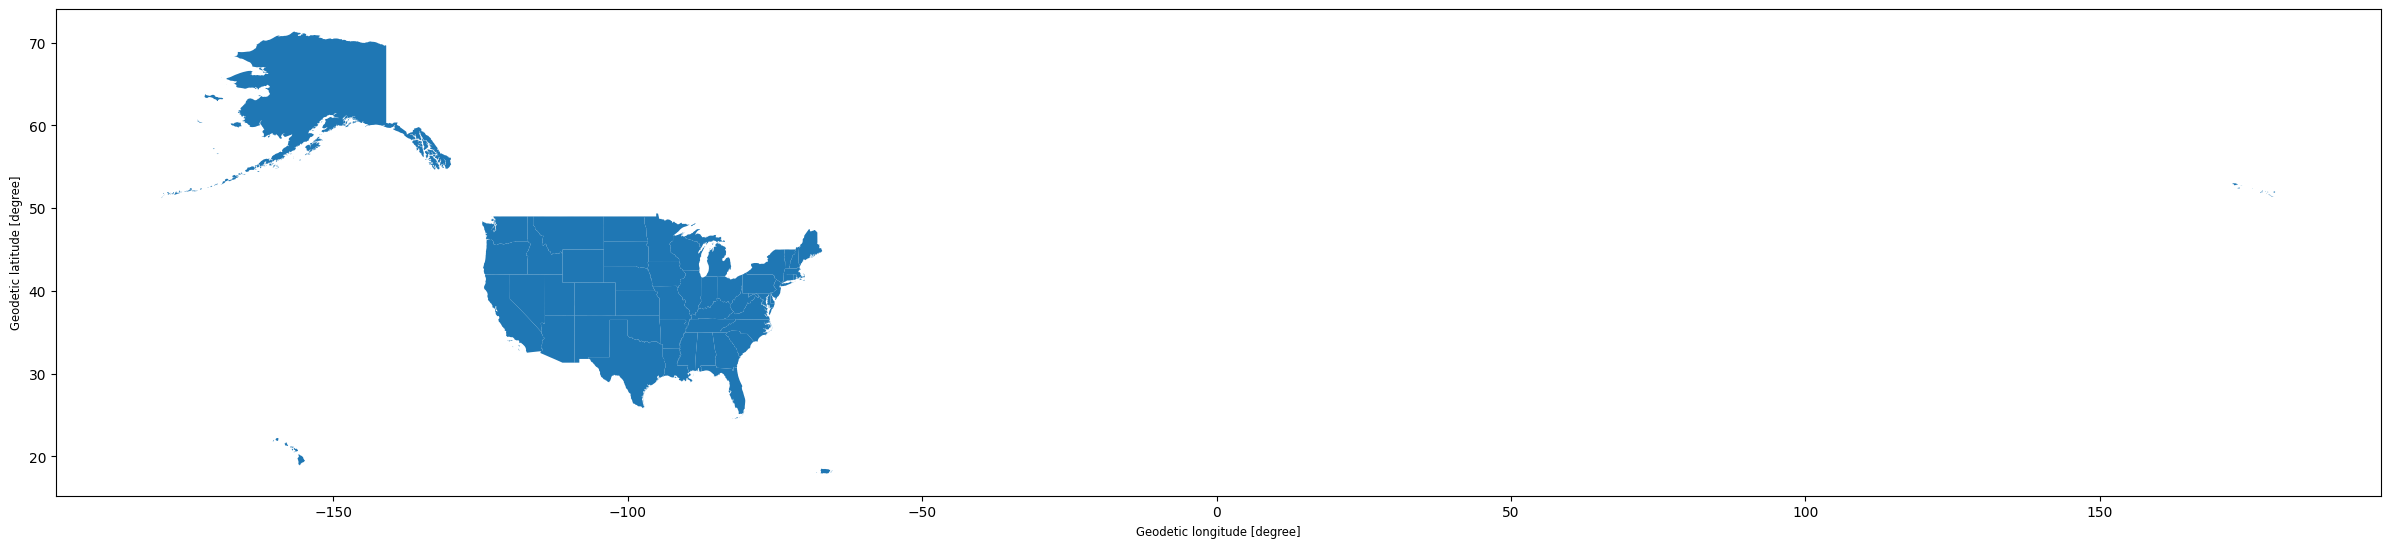

In [3]:
# Plot of the original figure
country.plot(figsize=(30,20))

As `.isin()` returns a Series of booleans with the same shape as the input object, with True if the value is in the list and False otherwise, I tried to exclude the 2 states by putting a `not` to invert the result of `.isin()`

In [10]:
# Removing Alaska and Hawai with not
Alaska_Hawai = ["Alaska","Hawaii"]

try:
  country_min_Alaska_Hawai = not(country["NAME"].isin(Alaska_Hawai))
except ValueError as err:
  print("ValueError:", err)

ValueError: The truth value of a Series is ambiguous. Use a.empty, a.bool(), a.item(), a.any() or a.all().


This raised a "ValueError: The truth value of a Series is ambiguous." and suggested to use `.any()` or `.all()` instead

In [13]:
try:
  country_min_Alaska_Hawai = (country["NAME"].isin(Alaska_Hawai)).any()
  print(country_min_Alaska_Hawai, type(country_min_Alaska_Hawai))
  country[country_min_Alaska_Hawai].plot(figsize=(30,20))
except KeyError as err:
  print("KeyError", err)

True <class 'numpy.bool'>
KeyError np.True_


This did not work as .any() just check if there was Alaska or Hawai in the Series

# Solution

The solution is to use `~` as presented in exercise 1.4 which invert the value element by element.

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

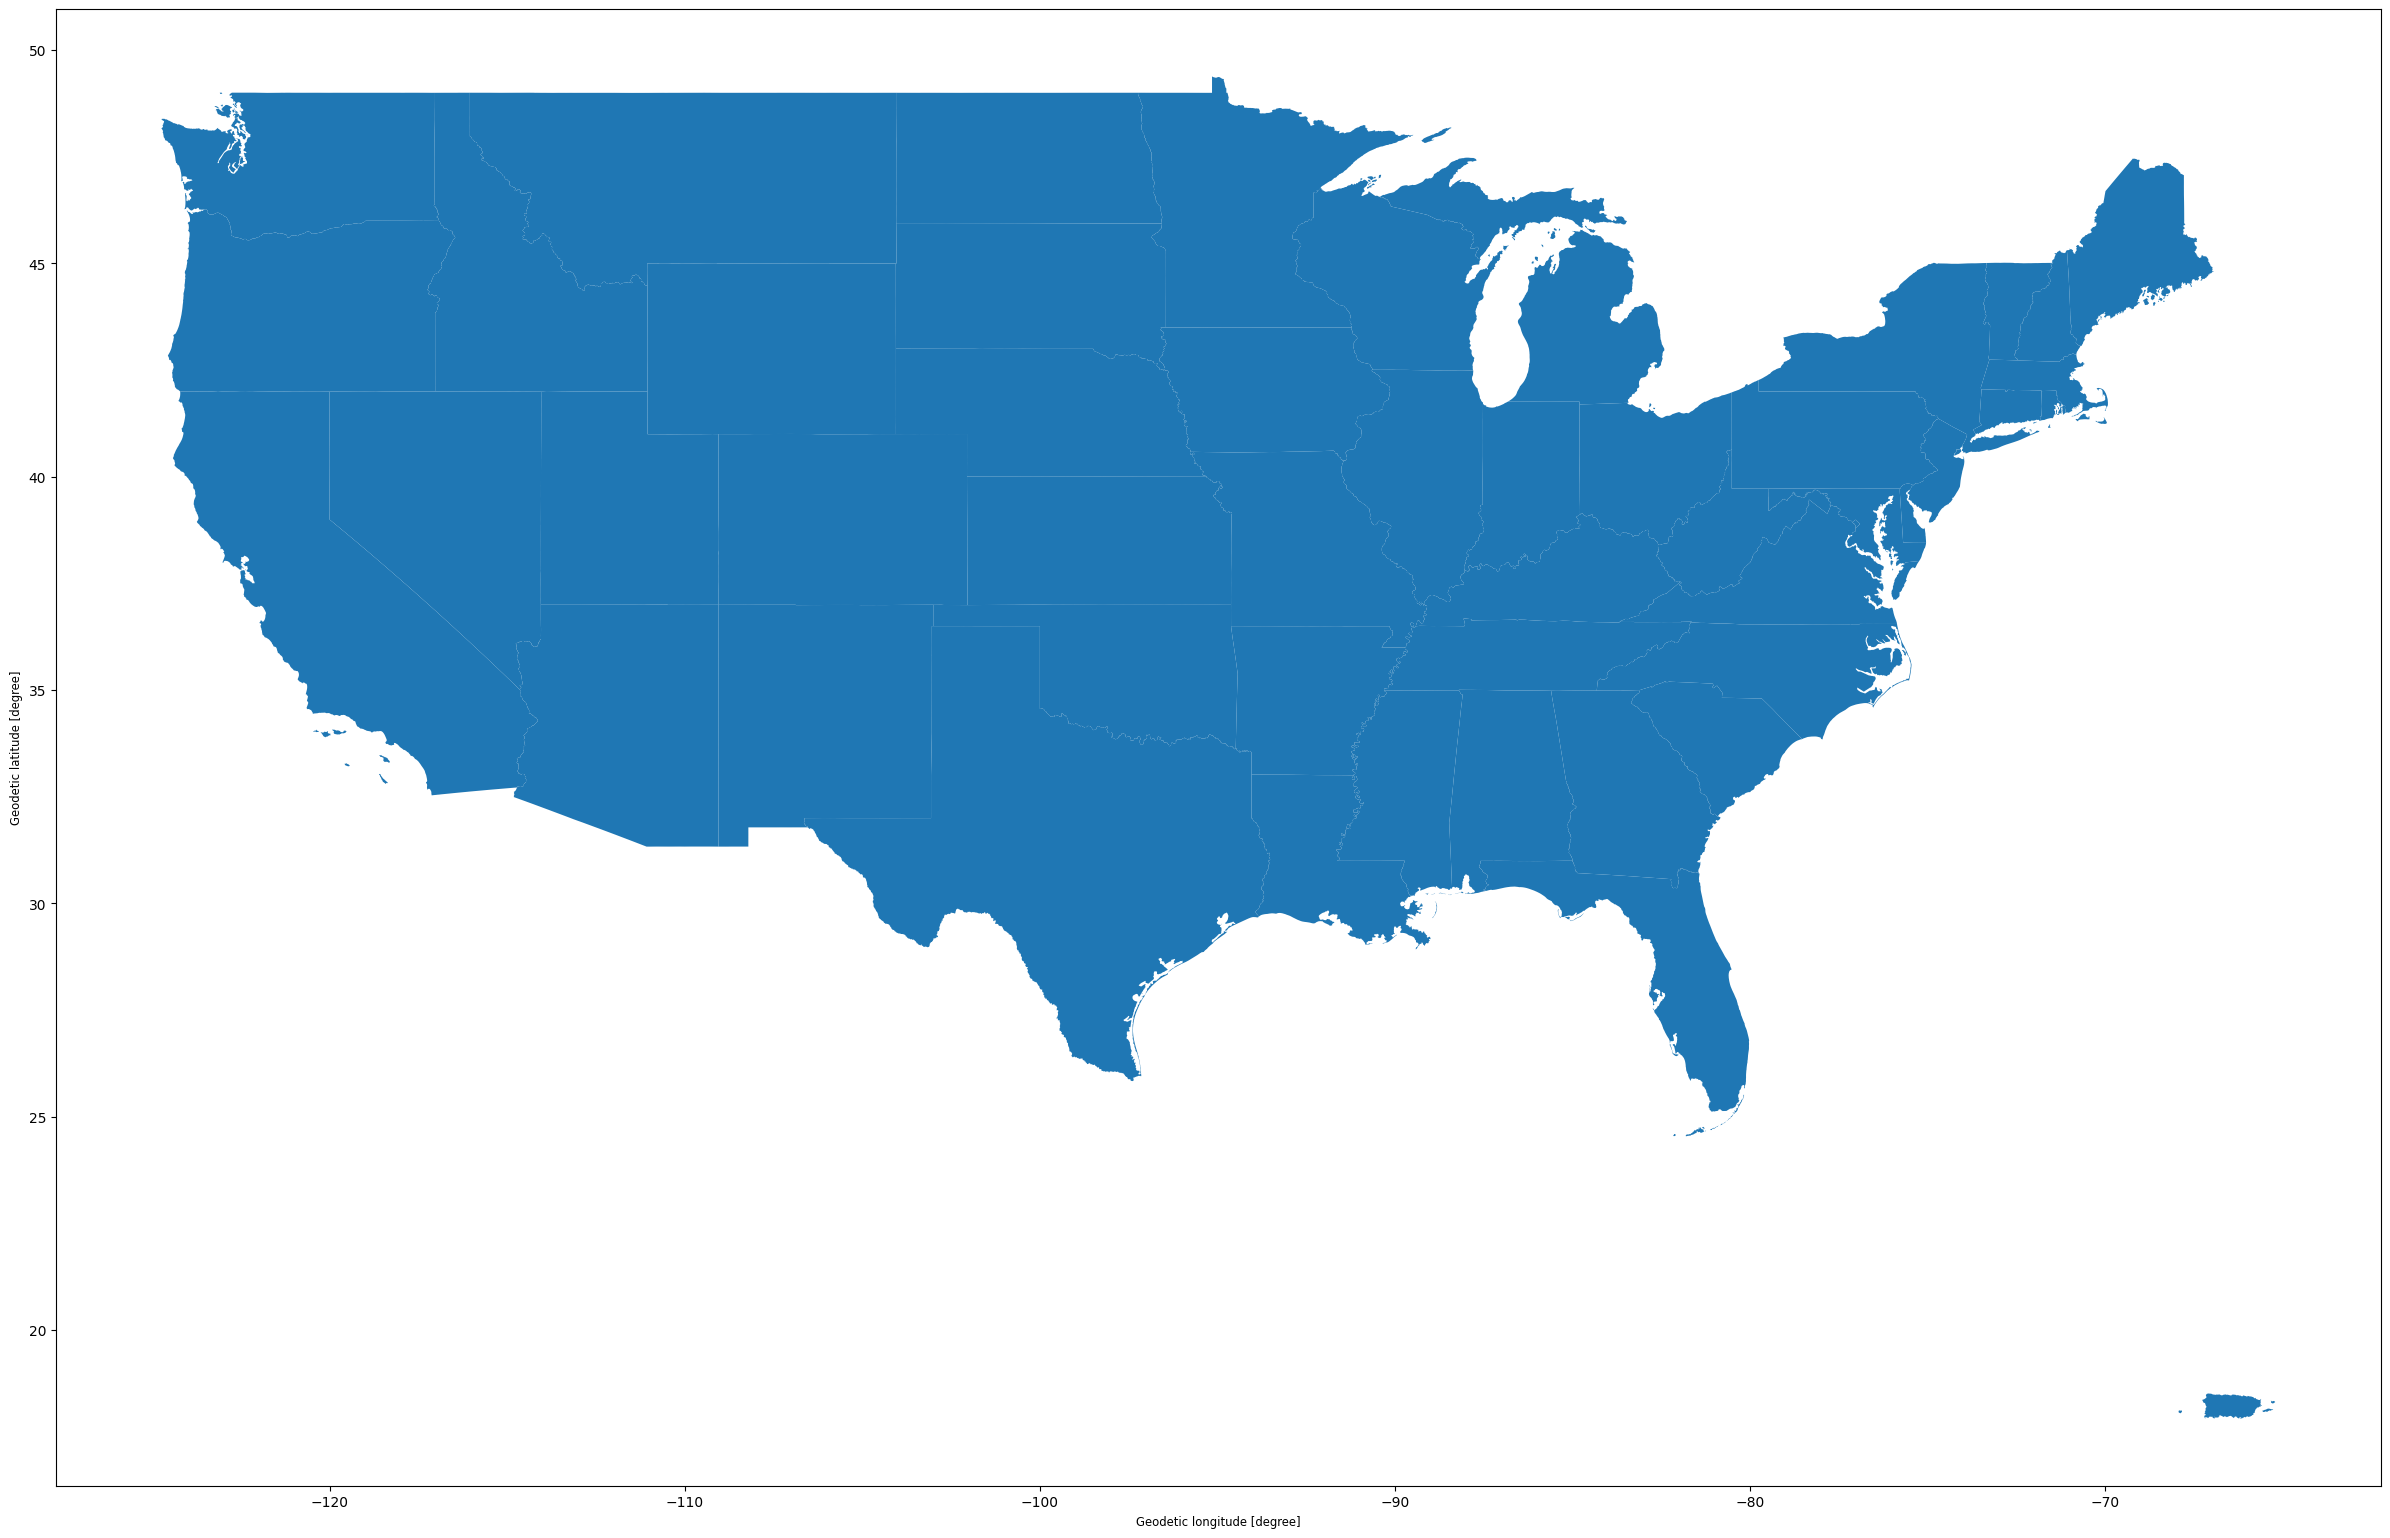

In [12]:
country_min_Alaska_Hawai = ~(country["NAME"].isin(Alaska_Hawai))
country[country_min_Alaska_Hawai].plot(figsize=(30,20))

I knew that `and` and `or` do not work element-wise on Series. So now I have learned that `not`neither as it worked on the whole object and not on each element.